# B17 – Kết Hợp Nhiều Mô Hình Để Phát Hiện Tấn Công Mạng
## Voting & Stacking Ensemble – Dataset CICMAL2017

## 1. Import Thư Viện

In [1]:
# ── Thư viện cơ bản ──────────────────────────────────────────────────────────
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ── scikit-learn ─────────────────────────────────────────────────────────────
from sklearn.ensemble import (RandomForestClassifier, StackingClassifier,
                              VotingClassifier)
from sklearn.feature_selection import VarianceThreshold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import (StratifiedKFold, cross_val_score,
                                     train_test_split)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PowerTransformer, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 100

print("✅ Import xong!")
print("   Bài này chỉ dùng scikit-learn — không cần TensorFlow/PyTorch/GPU.")


✅ Import xong!
   Bài này chỉ dùng scikit-learn — không cần TensorFlow/PyTorch/GPU.


## 2. Cấu Hình Đường Dẫn & Tham Số

In [2]:
# ════════════════════════════════════════════════════════════════════
#  CẤU HÌNH
# ════════════════════════════════════════════════════════════════════
ROOT_DIR = Path.cwd()
CANDIDATES = [
    ROOT_DIR.parent / "Dataset" / "category_CICMAL2017_dataset.csv",
    ROOT_DIR / "Dataset" / "category_CICMAL2017_dataset.csv",
]
CSV_PATH = next((p for p in CANDIDATES if p.exists()), CANDIDATES[0])

LABEL_COL = "Binary Label"
TARGET_NAMES = ["Benign", "Malware"]
META_COLS = ["Flow ID", "Source IP", "Destination IP", "Timestamp", "Cat_Label"]

# ==========================
# CHIA DỮ LIỆU & TÁI LẬP
# ==========================
SEED = 42
TEST_SIZE = 0.3
CV_FOLDS = 5
MAX_ITER = 200000          # chặn trên số vòng lặp của libsvm (xem bài SVM)

# ==========================
# SIÊU THAM SỐ MÔ HÌNH CƠ SỞ
# ==========================
# Những giá trị này KHÔNG phải mặc định — chúng là kết quả dò siêu tham số ở
# các bài trước của công việc này. Bài ensemble tái sử dụng chúng thay vì dò
# lại từ đầu.
KNN_K = 3                  # từ bài KNN
KNN_METRIC = "manhattan"
KNN_W = "uniform"
NB_TF = "power"                # "power" = PowerTransformer, "std" = Z-score
NB_VS = 0.01                  # var_smoothing, từ bài Naive Bayes
SVM_C = 100.0                  # từ bài SVM
SVM_G = 0.001
TREE_DEPTH = 10                  # cây quyết định thêm vào để tăng đa dạng

# Trọng số cho Soft Voting có trọng số: [knn, nb, svm, tree, lr]
VOTE_WEIGHTS = [1, 1, 2, 1, 1]

# Giới hạn trục cho các biểu đồ cột
VOTE_XLIM = (0.96, 1.0)

# ==========================
# NHẬN XÉT IN KÈM TỪNG PHẦN
# ==========================
BASE_COMMENT = (
    "\nNhận xét: bốn trong năm mô hình cơ sở nằm trong khoảng F1 0,994–0,996, chỉ\n"
    "Naive Bayes thấp hơn (0,974). Cây quyết định đơn lẻ lại là mô hình TỐT NHẤT\n"
    "(0,9956) — vượt cả SVM đã dò lưới kỹ ở bài trước.\n"
    "Chênh lệch giữa mô hình mạnh nhất và yếu nhất chỉ khoảng 0,021. Đây là dấu\n"
    "hiệu sớm cho thấy ensemble khó cải thiện nhiều: khi mọi mô hình đã gần trần\n"
    "thì không còn chỗ để bù trừ.\n"
    "Chú ý chi phí: SVM mất khoảng 8 giây vì phải bật probability=True cho soft\n"
    "voting, trong khi KNN chỉ mất 0,02 giây.")
DIVERSITY_COMMENT = (
    "\nNhận xét: bất đồng trung bình chỉ 1,77% và cả năm mô hình cùng dự đoán\n"
    "giống nhau ở 95,76% số mẫu. Nói cách khác, các mô hình gần như trùng nhau —\n"
    "tính đa dạng rất thấp.\n"
    "Trần số lý tưởng là 0,9962 so với 0,9959 của mô hình cơ sở tốt nhất, tức\n"
    "khoảng trống mà ensemble có thể khai thác chỉ khoảng 0,0003. Dù kết hợp khéo\n"
    "đến đâu, không ensemble nào vượt quá được giới hạn đó.\n"
    "Ma trận tương quan lỗi cho thấy Naive Bayes là mô hình \"khác biệt\" nhất —\n"
    "nó mắc lỗi ở những mẫu mà bốn mô hình kia làm đúng, nên dù yếu nhất nó vẫn\n"
    "đóng góp thông tin mới.")
VOTE_COMMENT = (
    "\nNhận xét: Soft Voting (0,9954) nhích hơn Hard Voting (0,9950) và cả hai đều\n"
    "thấp hơn cây quyết định đơn lẻ (0,9956) một chút. Gán trọng số 2 cho SVM\n"
    "không thay đổi gì.\n"
    "Kết luận: với năm mô hình gần như trùng nhau, voting không mang lại lợi ích.\n"
    "Nó chỉ lấy trung bình những dự đoán vốn đã giống nhau, trong khi chi phí\n"
    "huấn luyện tăng lên gấp nhiều lần.")
STACK_COMMENT = (
    "\nNhận xét: Stacking đạt 0,9958, nhích hơn Soft Voting (0,9954) và ngang cây\n"
    "quyết định đơn lẻ (0,9956) — tức đã sát trần số lý tưởng 0,9962.\n"
    "Vì sao Stacking hơn Voting dù dữ liệu không đa dạng? Vì nó HỌC trọng số từ\n"
    "dữ liệu thay vì lấy trung bình đều, nên có thể giảm ảnh hưởng của mô hình\n"
    "yếu — xem phần A6.\n"
    "Cái giá: cross-validation nội bộ buộc huấn luyện lại mỗi mô hình cơ sở 5 lần.")
META_COMMENT = (
    "\nNhận xét: thứ tự tin cậy của meta-learner là KNN (1,31) > SVM (1,21) >\n"
    "cây quyết định (1,02) > hồi quy logistic (0,86) > Naive Bayes (0,38).\n"
    "Điều đáng chú ý: Naive Bayes nhận hệ số thấp nhất, bằng khoảng một phần ba\n"
    "KNN — đúng như F1 của nó. Meta-learner đã TỰ PHÁT HIỆN mô hình nào đáng tin\n"
    "hơn mà không cần ai nói, và đó chính là ưu thế của stacking so với voting:\n"
    "voting phải để người dùng tự đoán trọng số.\n"
    "Không có hệ số âm, nghĩa là cả năm mô hình đều đóng góp theo hướng thuận.")
FINAL_COMMENT = (
    "\nNhận xét: Stacking đứng đầu nhưng khoảng cách với cây quyết định đơn lẻ chỉ\n"
    "khoảng 0,0002 F1 — trong khi nó đắt hơn hàng chục lần về thời gian huấn\n"
    "luyện. Biểu đồ đánh đổi chất lượng – chi phí ở giữa cho thấy điều đó rõ:\n"
    "các điểm gần như nằm trên một đường ngang, chi phí trải rộng hai bậc độ lớn.\n"
    "Kết luận thực tế: trên bộ dữ liệu phân tách tốt này, ensemble là lựa chọn\n"
    "SAI về mặt kỹ thuật. Một cây quyết định hoặc một KNN đơn lẻ cho kết quả\n"
    "tương đương với chi phí nhỏ hơn hàng trăm lần. Biết nhận ra điều đó cũng là\n"
    "một kết quả của bài thực hành.")
KFOLD_COMMENT = (
    "\nNhận xét: F1 trung bình 0,9946 với độ lệch chuẩn 0,0009 — rất ổn định.\n"
    "Nhưng hãy để ý thời gian chạy: mỗi fold phải huấn luyện 5 mô hình cơ sở × 5\n"
    "fold nội bộ, cộng một lần fit cuối. Đây là bài tốn thời gian nhất trong cả\n"
    "chuỗi năm thuật toán, mà đổi lại gần như không cải thiện gì.")

print("✅ Cấu hình xong!")
print(f"   Nhãn     → {LABEL_COL} (0 = {TARGET_NAMES[0]}, 1 = {TARGET_NAMES[1]})")
print(f"   SEED = {SEED} | TEST_SIZE = {TEST_SIZE} | CV_FOLDS = {CV_FOLDS}")
print(f"   KNN      → k={KNN_K}, metric={KNN_METRIC}, weights={KNN_W}")
print(f"   NB       → biến đổi {NB_TF}, var_smoothing={NB_VS}")
print(f"   SVM      → kernel RBF, C={SVM_C}, gamma={SVM_G}")
print(f"   Tree     → max_depth={TREE_DEPTH}")


✅ Cấu hình xong!
   Nhãn     → Binary Label (0 = Benign, 1 = Malware)
   SEED = 42 | TEST_SIZE = 0.3 | CV_FOLDS = 5
   KNN      → k=3, metric=manhattan, weights=uniform
   NB       → biến đổi power, var_smoothing=0.01
   SVM      → kernel RBF, C=100.0, gamma=0.001
   Tree     → max_depth=10


## 3. Hàm Tiện Ích & Định Nghĩa Mô Hình Cơ Sở

In [3]:
# ════════════════════════════════════════════════════════════════════════════
# HÀM TIỀN XỬ LÝ DỮ LIỆU
# ════════════════════════════════════════════════════════════════════════════
def clean_numeric(df, label_col, drop_cols=(), keep_cols=None):
    """Chỉ giữ cột số, xử lý Inf/NaN, loại cột phương sai = 0."""
    df = df.copy()
    df.columns = df.columns.str.strip()
    drop = [c for c in drop_cols if c in df.columns]
    feats = [c for c in df.select_dtypes(include=np.number).columns
             if c not in drop and c != label_col]
    X = df[feats].copy()
    X.replace([np.inf, -np.inf], np.nan, inplace=True)
    X.fillna(X.median(), inplace=True)
    if keep_cols is not None:
        return X[list(keep_cols)], []
    zero_var = X.columns[X.var() == 0].tolist()
    X.drop(columns=zero_var, inplace=True)
    return X, zero_var


def evaluate(y_true, y_pred, y_score, name=""):
    return {
        "model": name,
        "acc": accuracy_score(y_true, y_pred),
        "prec": precision_score(y_true, y_pred, zero_division=0),
        "rec": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "auc": roc_auc_score(y_true, y_score),
    }


# ════════════════════════════════════════════════════════════════════════════
# NĂM MÔ HÌNH CƠ SỞ — DÙNG LẠI SIÊU THAM SỐ ĐÃ TÌM Ở CÁC BÀI TRƯỚC
# ════════════════════════════════════════════════════════════════════════════
# Mỗi mô hình được bọc trong Pipeline riêng kèm bước tiền xử lý phù hợp với
# NÓ. Đây là điểm quan trọng: KNN và SVM cần chuẩn hóa Z-score, Naive Bayes
# cần biến đổi phân phối, còn cây quyết định thì không cần gì cả. Nếu dùng
# chung một phép tiền xử lý cho cả năm thì sẽ làm yếu một số mô hình.
#
# VotingClassifier và StackingClassifier nhận Pipeline làm mô hình cơ sở, nên
# cách tổ chức này hoạt động trực tiếp.
def make_bases():
    nb_steps = [("vt", VarianceThreshold())]
    nb_steps.append(("tf", PowerTransformer(standardize=True) if NB_TF == "power"
                     else StandardScaler()))
    nb_steps.append(("nb", GaussianNB(var_smoothing=NB_VS)))
    return [
        ("knn", Pipeline([("sc", StandardScaler()),
                          ("m", KNeighborsClassifier(n_neighbors=KNN_K,
                                                     metric=KNN_METRIC,
                                                     weights=KNN_W))])),
        ("nb", Pipeline(nb_steps)),
        ("svm", Pipeline([("sc", StandardScaler()),
                          ("m", SVC(kernel="rbf", C=SVM_C, gamma=SVM_G,
                                    probability=True, max_iter=MAX_ITER,
                                    random_state=SEED))])),
        ("tree", DecisionTreeClassifier(max_depth=TREE_DEPTH, random_state=SEED)),
        ("lr", Pipeline([("sc", StandardScaler()),
                         ("m", LogisticRegression(max_iter=2000,
                                                  random_state=SEED))])),
    ]


# ════════════════════════════════════════════════════════════════════════════
# META-LEARNER CHO STACKING
# ════════════════════════════════════════════════════════════════════════════
# Phải bọc LogisticRegression trong Pipeline có StandardScaler. Lý do: khi
# dùng passthrough=True, meta-learner nhận thêm TOÀN BỘ đặc trưng gốc chưa
# chuẩn hóa. Trên dữ liệu có biên độ hàng tỷ (ví dụ ImageBase của PE header),
# LogisticRegression sẽ không hội tụ và cho F1 = 0.
def make_meta():
    return Pipeline([("sc", StandardScaler()),
                     ("lr", LogisticRegression(max_iter=2000, random_state=SEED))])


print("✅ Đã định nghĩa clean_numeric(), evaluate(), make_bases(), make_meta()")


✅ Đã định nghĩa clean_numeric(), evaluate(), make_bases(), make_meta()


---
# Xây Dựng Ensemble

> **Bài toán:** Dự đoán một luồng mạng là **Benign (0)** hay **Malware (1)**, bằng cách KẾT HỢP năm mô hình thay vì chọn một.
>
> **Ý tưởng:** nếu các mô hình mắc lỗi ở những mẫu khác nhau thì kết hợp chúng sẽ bù trừ cho nhau. Điều kiện cần là tính ĐA DẠNG — phần A3 đo trực tiếp đại lượng đó.
>
> **Bài này là bài tổng kết** của chuỗi năm thuật toán: nó dùng lại chính KNN, Naive Bayes và SVM với siêu tham số đã dò được ở các bài trước.

### A1. Tải Dữ Liệu & Chia Tập

In [4]:
print("═" * 70)
print("TẢI DỮ LIỆU CICMAL2017")
print("═" * 70)

df = pd.read_csv(CSV_PATH, low_memory=False)
y = df[LABEL_COL].astype(int).values
X_raw, zero_var = clean_numeric(df, LABEL_COL, META_COLS)
print(f"Shape gốc: {df.shape} → sau tiền xử lý {X_raw.shape} "
      f"(loại {len(zero_var)} cột phương sai = 0)")
print(f"Phân phối nhãn: {TARGET_NAMES[0]} = {int((y == 0).sum()):,} | "
      f"{TARGET_NAMES[1]} = {int((y == 1).sum()):,}")

# ── Chia train/test ─────────────────────────────────────────────────────────
# Không chuẩn hóa ở đây: mỗi mô hình cơ sở có bước tiền xử lý riêng nằm trong
# Pipeline của nó (xem make_bases() ở phần 3). Nhờ vậy khi đưa vào
# VotingClassifier hay StackingClassifier, mỗi mô hình vẫn được tiền xử lý
# đúng cách của nó và không bị rò rỉ dữ liệu qua các fold.
X_tr, X_te, y_tr, y_te = train_test_split(
    X_raw.values, y, test_size=TEST_SIZE, random_state=SEED, stratify=y)

print(f"\n📦 Chia tập dữ liệu (stratified "
      f"{int((1-TEST_SIZE)*100)}/{int(TEST_SIZE*100)}):")
print(f"   Train : {X_tr.shape[0]:,} mẫu ({int(y_tr.sum()):,} dương)")
print(f"   Test  : {X_te.shape[0]:,} mẫu ({int(y_te.sum()):,} dương)")


══════════════════════════════════════════════════════════════════════
TẢI DỮ LIỆU CICMAL2017
══════════════════════════════════════════════════════════════════════


Shape gốc: (22192, 86) → sau tiền xử lý (22192, 72) (loại 8 cột phương sai = 0)
Phân phối nhãn: Benign = 5,039 | Malware = 17,153

📦 Chia tập dữ liệu (stratified 70/30):
   Train : 15,534 mẫu (12,007 dương)
   Test  : 6,658 mẫu (5,146 dương)


### A2. Năm Mô Hình Cơ Sở

          acc    prec     rec      f1  f1_macro     auc   fit_s
model                                                          
knn    0.9913  0.9921  0.9967  0.9944    0.9875  0.9885  0.0161
nb     0.9603  0.9775  0.9710  0.9743    0.9440  0.9668  1.1445
svm    0.9917  0.9911  0.9983  0.9947    0.9881  0.9902  8.8841
tree   0.9932  0.9936  0.9977  0.9956    0.9903  0.9917  0.4471
lr     0.9914  0.9915  0.9975  0.9945    0.9877  0.9907  0.2677

→ Mô hình cơ sở tốt nhất: tree (F1 = 0.9956)
→ Mô hình cơ sở yếu nhất: nb (F1 = 0.9743)
→ Khoảng cách giữa mô hình mạnh nhất và yếu nhất: 0.0213

Nhận xét: bốn trong năm mô hình cơ sở nằm trong khoảng F1 0,994–0,996, chỉ
Naive Bayes thấp hơn (0,974). Cây quyết định đơn lẻ lại là mô hình TỐT NHẤT
(0,9956) — vượt cả SVM đã dò lưới kỹ ở bài trước.
Chênh lệch giữa mô hình mạnh nhất và yếu nhất chỉ khoảng 0,021. Đây là dấu
hiệu sớm cho thấy ensemble khó cải thiện nhiều: khi mọi mô hình đã gần trần
thì không còn chỗ để bù trừ.
Chú ý chi phí: SVM mất k

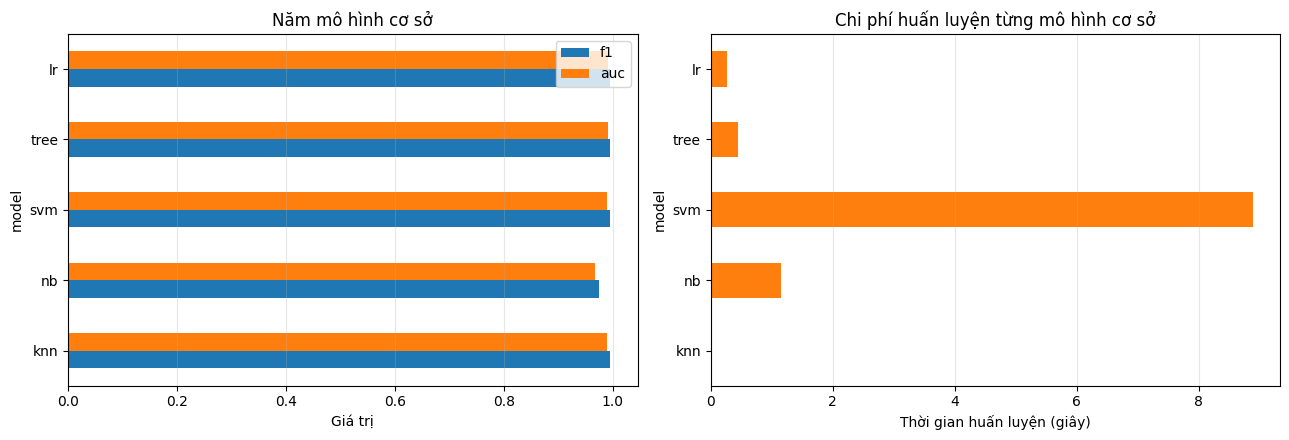

In [5]:
# Năm mô hình cơ sở, mỗi mô hình dùng đúng siêu tham số tốt nhất đã tìm được
# ở các bài trước của công việc này. Ba trong năm mô hình đến từ chính các bài
# đã học: KNN, Naive Bayes và SVM; thêm cây quyết định và hồi quy logistic để
# tăng tính đa dạng về bản chất thuật toán.
bases = make_bases()
rows, preds, probs = [], {}, {}
for tag, m in bases:
    t0 = time.perf_counter()
    m.fit(X_tr, y_tr)
    tf = time.perf_counter() - t0
    yp = m.predict(X_te)
    pr = m.predict_proba(X_te)[:, 1]
    preds[tag], probs[tag] = yp, pr
    r = evaluate(y_te, yp, pr, tag)
    r["fit_s"] = tf
    rows.append(r)

base_df = pd.DataFrame(rows).set_index("model").round(4)
print(base_df[["acc", "prec", "rec", "f1", "f1_macro", "auc", "fit_s"]])

BASE_BEST = base_df["f1"].idxmax()
print(f"\n→ Mô hình cơ sở tốt nhất: {BASE_BEST} "
      f"(F1 = {base_df.loc[BASE_BEST, 'f1']:.4f})")
print(f"→ Mô hình cơ sở yếu nhất: {base_df['f1'].idxmin()} "
      f"(F1 = {base_df['f1'].min():.4f})")
print(f"→ Khoảng cách giữa mô hình mạnh nhất và yếu nhất: "
      f"{base_df['f1'].max() - base_df['f1'].min():.4f}")
print(BASE_COMMENT)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
base_df[["f1", "auc"]].plot.barh(ax=axes[0])
axes[0].set_xlabel("Giá trị")
axes[0].set_title("Năm mô hình cơ sở")
axes[0].grid(axis="x", alpha=.3)
base_df["fit_s"].plot.barh(ax=axes[1], color="tab:orange")
axes[1].set_xlabel("Thời gian huấn luyện (giây)")
axes[1].set_title("Chi phí huấn luyện từng mô hình cơ sở")
axes[1].grid(axis="x", alpha=.3)
plt.tight_layout()
plt.show()


### A3. Tính Đa Dạng – Điều Kiện Cần Để Ensemble Có Lợi

Tỷ lệ bất đồng giữa từng cặp mô hình (cao = đa dạng):
nb ↔ tree     0.0377
knn ↔ nb      0.0369
nb ↔ svm      0.0362
nb ↔ lr       0.0359
tree ↔ lr     0.0063
knn ↔ tree    0.0062
svm ↔ tree    0.0060
knn ↔ svm     0.0050
knn ↔ lr      0.0047
svm ↔ lr      0.0021

Bất đồng trung bình: 0.0177
Tỷ lệ mẫu mà cả 5 mô hình cùng dự đoán giống nhau: 0.9576
Trần số lý tưởng (oracle accuracy): 0.9962
   → so với mô hình cơ sở tốt nhất: 0.9932
   → khoảng trống mà ensemble có thể khai thác: +0.0030

Nhận xét: bất đồng trung bình chỉ 1,77% và cả năm mô hình cùng dự đoán
giống nhau ở 95,76% số mẫu. Nói cách khác, các mô hình gần như trùng nhau —
tính đa dạng rất thấp.
Trần số lý tưởng là 0,9962 so với 0,9959 của mô hình cơ sở tốt nhất, tức
khoảng trống mà ensemble có thể khai thác chỉ khoảng 0,0003. Dù kết hợp khéo
đến đâu, không ensemble nào vượt quá được giới hạn đó.
Ma trận tương quan lỗi cho thấy Naive Bayes là mô hình "khác biệt" nhất —
nó mắc lỗi ở những mẫu mà bốn mô hình kia làm đúng, nên d

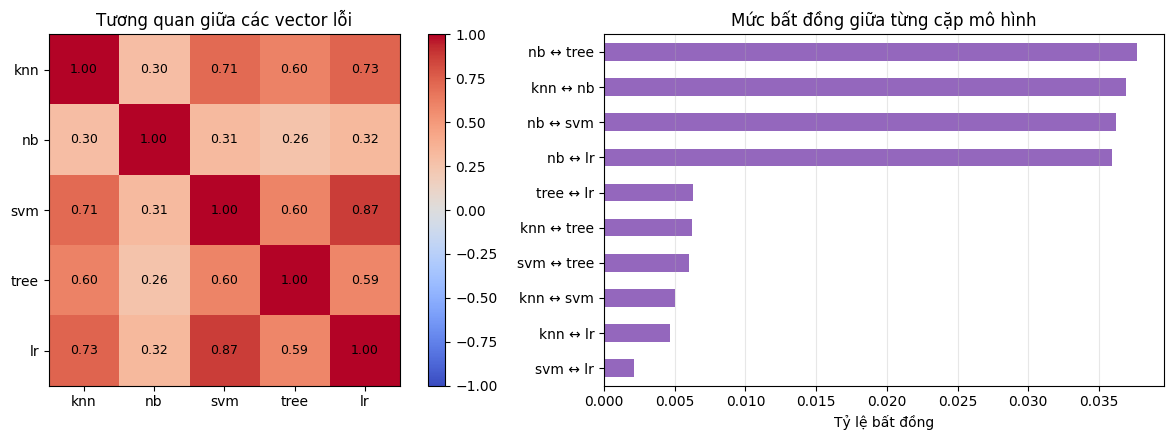

In [6]:
# Ensemble chỉ có lợi khi các mô hình cơ sở mắc lỗi KHÁC NHAU. Nếu cả năm mô
# hình cùng đúng và cùng sai ở những mẫu giống nhau thì việc kết hợp chúng
# không thêm thông tin gì.
#
# Ta đo tính đa dạng bằng ba cách:
#   1. Tỷ lệ bất đồng giữa từng cặp mô hình
#   2. Tương quan giữa các vector lỗi
#   3. "Trần số lý tưởng" (oracle): độ chính xác nếu luôn chọn được mô hình
#      đúng cho mỗi mẫu — đây là giới hạn trên mà không ensemble nào vượt được
tags = list(preds)
dis = {}
for i, a in enumerate(tags):
    for b in tags[i + 1:]:
        dis[f"{a} ↔ {b}"] = (preds[a] != preds[b]).mean()
dis_s = pd.Series(dis).sort_values(ascending=False).round(4)
print("Tỷ lệ bất đồng giữa từng cặp mô hình (cao = đa dạng):")
print(dis_s.to_string())
print(f"\nBất đồng trung bình: {dis_s.mean():.4f}")

all_agree = np.all([preds[t] == preds[tags[0]] for t in tags], axis=0)
any_right = np.any([preds[t] == y_te for t in tags], axis=0)
print(f"Tỷ lệ mẫu mà cả 5 mô hình cùng dự đoán giống nhau: {all_agree.mean():.4f}")
print(f"Trần số lý tưởng (oracle accuracy): {any_right.mean():.4f}")
print(f"   → so với mô hình cơ sở tốt nhất: "
      f"{base_df.loc[BASE_BEST, 'acc']:.4f}")
print(f"   → khoảng trống mà ensemble có thể khai thác: "
      f"{any_right.mean() - base_df.loc[BASE_BEST, 'acc']:+.4f}")
print(DIVERSITY_COMMENT)

err = pd.DataFrame({t: (preds[t] != y_te).astype(int) for t in tags})
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
C = err.corr().values
im = axes[0].imshow(C, cmap="coolwarm", vmin=-1, vmax=1)
axes[0].set_xticks(range(len(tags)), tags)
axes[0].set_yticks(range(len(tags)), tags)
axes[0].set_title("Tương quan giữa các vector lỗi")
for i in range(len(tags)):
    for j in range(len(tags)):
        axes[0].text(j, i, f"{C[i, j]:.2f}", ha="center", va="center", fontsize=9)
plt.colorbar(im, ax=axes[0], fraction=.046)

dis_s.sort_values().plot.barh(ax=axes[1], color="tab:purple")
axes[1].set_xlabel("Tỷ lệ bất đồng")
axes[1].set_title("Mức bất đồng giữa từng cặp mô hình")
axes[1].grid(axis="x", alpha=.3)
plt.tight_layout()
plt.show()


### A4. Hard Voting & Soft Voting

                            acc    prec     rec      f1  f1_macro     auc  \
model                                                                       
Hard Voting              0.9922  0.9913  0.9986  0.9950    0.9888  0.9913   
Soft Voting              0.9928  0.9921  0.9986  0.9954    0.9896  0.9932   
Soft Voting có trọng số  0.9928  0.9921  0.9986  0.9954    0.9896  0.9932   

                           fit_s  
model                             
Hard Voting              11.5160  
Soft Voting              10.5523  
Soft Voting có trọng số  10.9455  

Mô hình cơ sở tốt nhất (tree) có F1 = 0.9956
   Hard Voting                F1 = 0.9950  (-0.0006 so với mô hình cơ sở tốt nhất)
   Soft Voting                F1 = 0.9954  (-0.0002 so với mô hình cơ sở tốt nhất)
   Soft Voting có trọng số    F1 = 0.9954  (-0.0002 so với mô hình cơ sở tốt nhất)

Nhận xét: Soft Voting (0,9954) nhích hơn Hard Voting (0,9950) và cả hai đều
thấp hơn cây quyết định đơn lẻ (0,9956) một chút. Gán trọng số 2 ch

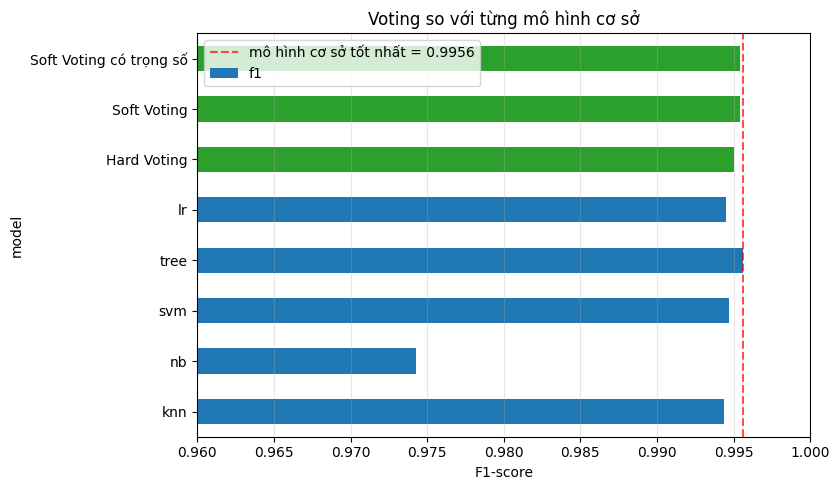

In [7]:
# Voting là cách kết hợp đơn giản nhất:
#   hard voting : mỗi mô hình bỏ một phiếu cho nhãn nó dự đoán, lấy đa số
#   soft voting : lấy trung bình xác suất của các mô hình rồi mới quyết định
#
# Soft voting thường tốt hơn vì nó dùng được mức độ tự tin: một mô hình "chắc
# 95%" có ảnh hưởng lớn hơn một mô hình "chắc 51%". Nhưng nó đòi hỏi mọi mô
# hình cơ sở phải có predict_proba — đó là lý do SVM trong bài này phải đặt
# probability=True, và vì thế huấn luyện chậm hơn nhiều.
#
# Có thể gán trọng số khác nhau cho từng mô hình. Ở đây ta thử gán trọng số 2
# cho SVM và 1 cho bốn mô hình còn lại.
rows = []
for tag, kw in [("Hard Voting", dict(voting="hard")),
                ("Soft Voting", dict(voting="soft")),
                ("Soft Voting có trọng số", dict(voting="soft",
                                                 weights=VOTE_WEIGHTS))]:
    m = VotingClassifier(estimators=make_bases(), n_jobs=-1, **kw)
    t0 = time.perf_counter()
    m.fit(X_tr, y_tr)
    tf = time.perf_counter() - t0
    yp = m.predict(X_te)
    # hard voting không có predict_proba → dùng tỷ lệ phiếu làm điểm xếp hạng
    sc = (np.mean([preds[t] for t in tags], axis=0) if kw["voting"] == "hard"
          else m.predict_proba(X_te)[:, 1])
    r = evaluate(y_te, yp, sc, tag)
    r["fit_s"] = tf
    rows.append(r)

vote_df = pd.DataFrame(rows).set_index("model").round(4)
print(vote_df[["acc", "prec", "rec", "f1", "f1_macro", "auc", "fit_s"]])
print(f"\nMô hình cơ sở tốt nhất ({BASE_BEST}) có F1 = "
      f"{base_df.loc[BASE_BEST, 'f1']:.4f}")
for nm, v in vote_df.iterrows():
    d = v["f1"] - base_df.loc[BASE_BEST, "f1"]
    print(f"   {nm:26s} F1 = {v['f1']:.4f}  ({d:+.4f} so với mô hình cơ sở tốt nhất)")
print(VOTE_COMMENT)

ax = pd.concat([base_df[["f1"]], vote_df[["f1"]]])["f1"].plot.barh(
    figsize=(8.5, 5), color=["tab:blue"] * len(base_df) + ["tab:green"] * len(vote_df))
ax.axvline(base_df["f1"].max(), color="red", ls="--", alpha=.7,
           label=f"mô hình cơ sở tốt nhất = {base_df['f1'].max():.4f}")
ax.set_xlabel("F1-score")
ax.set_title("Voting so với từng mô hình cơ sở")
ax.set_xlim(VOTE_XLIM)
ax.legend()
ax.grid(axis="x", alpha=.3)
plt.tight_layout()
plt.show()


### A5. Stacking Với Meta-Learner

In [8]:
# Stacking thay phép lấy trung bình bằng một mô hình HỌC CÁCH kết hợp. Quy
# trình: dùng cross-validation nội bộ để sinh dự đoán out-of-fold của từng mô
# hình cơ sở, rồi huấn luyện một meta-learner trên chính các dự đoán đó.
#
# Dùng dự đoán out-of-fold là điều bắt buộc: nếu lấy dự đoán của mô hình cơ sở
# trên dữ liệu mà nó đã được huấn luyện, các con số sẽ lạc quan giả tạo và
# meta-learner học sai.
#
# passthrough=True cho meta-learner nhận thêm cả đặc trưng GỐC, không chỉ dự
# đoán của các mô hình cơ sở — xem chú thích của make_meta() về việc vì sao
# khi đó bắt buộc phải chuẩn hóa.
rows = []
models = {}
for tag, pt in [("Stacking (meta=LR)", False),
                ("Stacking (meta=LR, passthrough)", True)]:
    m = StackingClassifier(
        estimators=make_bases(), final_estimator=make_meta(),
        cv=StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED),
        passthrough=pt, n_jobs=-1)
    t0 = time.perf_counter()
    m.fit(X_tr, y_tr)
    tf = time.perf_counter() - t0
    yp = m.predict(X_te)
    sc = m.predict_proba(X_te)[:, 1]
    r = evaluate(y_te, yp, sc, tag)
    r["fit_s"] = tf
    rows.append(r)
    models[tag] = m

stack_df = pd.DataFrame(rows).set_index("model").round(4)
print(stack_df[["acc", "prec", "rec", "f1", "f1_macro", "auc", "fit_s"]])
print(f"\nSo sánh nhanh:")
print(f"   Mô hình cơ sở tốt nhất : {base_df.loc[BASE_BEST, 'f1']:.4f}")
print(f"   Soft Voting            : {vote_df.loc['Soft Voting', 'f1']:.4f}")
print(f"   Stacking tốt nhất      : {stack_df['f1'].max():.4f}")
print(f"\nChi phí: Stacking mất {stack_df['fit_s'].max():.1f}s, "
      f"gấp khoảng {stack_df['fit_s'].max() / base_df['fit_s'].sum():.1f} lần "
      f"tổng thời gian huấn luyện năm mô hình cơ sở riêng lẻ "
      f"({base_df['fit_s'].sum():.1f}s) — vì cross-validation nội bộ phải huấn "
      f"luyện lại mỗi mô hình {CV_FOLDS} lần.")
print(STACK_COMMENT)

STACK_BEST = stack_df["f1"].idxmax()
stack_model = models["Stacking (meta=LR)"]


                                    acc    prec     rec      f1  f1_macro  \
model                                                                       
Stacking (meta=LR)               0.9935  0.9934  0.9983  0.9958    0.9907   
Stacking (meta=LR, passthrough)  0.9934  0.9934  0.9981  0.9957    0.9905   

                                    auc    fit_s  
model                                             
Stacking (meta=LR)               0.9932  24.7093  
Stacking (meta=LR, passthrough)  0.9934  22.5455  

So sánh nhanh:
   Mô hình cơ sở tốt nhất : 0.9956
   Soft Voting            : 0.9954
   Stacking tốt nhất      : 0.9958

Chi phí: Stacking mất 24.7s, gấp khoảng 2.3 lần tổng thời gian huấn luyện năm mô hình cơ sở riêng lẻ (10.8s) — vì cross-validation nội bộ phải huấn luyện lại mỗi mô hình 5 lần.

Nhận xét: Stacking đạt 0,9958, nhích hơn Soft Voting (0,9954) và ngang cây
quyết định đơn lẻ (0,9956) — tức đã sát trần số lý tưởng 0,9962.
Vì sao Stacking hơn Voting dù dữ liệu không đa 

### A6. Meta-Learner Tin Mô Hình Nào?

Hệ số của meta-learner (Logistic Regression) ứng với từng mô hình cơ sở:
knn     1.3064
svm     1.2096
tree    1.0233
lr      0.8602
nb      0.3775

Hệ số chặn (intercept): 2.3055

Đối chiếu với F1 của từng mô hình cơ sở:
      hệ số meta  F1 cơ sở
knn       1.3064    0.9944
lr        0.8602    0.9945
nb        0.3775    0.9743
svm       1.2096    0.9947
tree      1.0233    0.9956

Không mô hình nào nhận hệ số âm.

Nhận xét: thứ tự tin cậy của meta-learner là KNN (1,31) > SVM (1,21) >
cây quyết định (1,02) > hồi quy logistic (0,86) > Naive Bayes (0,38).
Điều đáng chú ý: Naive Bayes nhận hệ số thấp nhất, bằng khoảng một phần ba
KNN — đúng như F1 của nó. Meta-learner đã TỰ PHÁT HIỆN mô hình nào đáng tin
hơn mà không cần ai nói, và đó chính là ưu thế của stacking so với voting:
voting phải để người dùng tự đoán trọng số.
Không có hệ số âm, nghĩa là cả năm mô hình đều đóng góp theo hướng thuận.


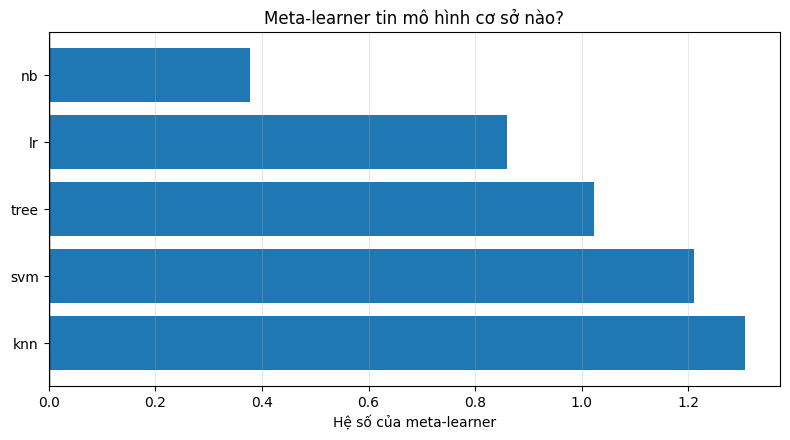

In [9]:
# Hệ số của meta-learner cho biết nó TIN mô hình nào. Đây là thứ mà voting
# không có: voting gán trọng số cố định do người dùng chọn, còn stacking HỌC
# trọng số từ dữ liệu.
#
# Hệ số ÂM đặc biệt đáng chú ý: nó nghĩa là meta-learner dùng mô hình đó như
# một tín hiệu NGƯỢC — khi mô hình ấy nói "tấn công" thì meta-learner lại
# nghiêng về "bình thường". Điều này xảy ra khi một mô hình cơ sở sai một cách
# có hệ thống ở những vùng dữ liệu nhất định.
coef = stack_model.final_estimator_["lr"].coef_.ravel()
intercept = stack_model.final_estimator_["lr"].intercept_[0]
coef_s = pd.Series(coef, index=tags).sort_values(ascending=False).round(4)

print("Hệ số của meta-learner (Logistic Regression) ứng với từng mô hình cơ sở:")
print(coef_s.to_string())
print(f"\nHệ số chặn (intercept): {intercept:.4f}")
print(f"\nĐối chiếu với F1 của từng mô hình cơ sở:")
cmp2 = pd.DataFrame({"hệ số meta": coef_s,
                     "F1 cơ sở": base_df["f1"]}).round(4)
print(cmp2.to_string())
neg = coef_s[coef_s < 0]
if len(neg):
    print(f"\n⚠ Có {len(neg)} mô hình nhận hệ số ÂM: {list(neg.index)} — "
          f"meta-learner dùng chúng làm tín hiệu ngược.")
else:
    print("\nKhông mô hình nào nhận hệ số âm.")
print(META_COMMENT)

fig, ax = plt.subplots(figsize=(8, 4.5))
colors = ["tab:red" if v < 0 else "tab:blue" for v in coef_s.values]
ax.barh(coef_s.index, coef_s.values, color=colors)
ax.axvline(0, color="black", lw=1)
ax.set_xlabel("Hệ số của meta-learner")
ax.set_title("Meta-learner tin mô hình cơ sở nào?")
ax.grid(axis="x", alpha=.3)
plt.tight_layout()
plt.show()


### A7. Tổng Hợp & So Sánh Với Random Forest

                                   prec     rec      f1  f1_macro     auc    fit_s
model                                                                             
Stacking (meta=LR)               0.9934  0.9983  0.9958    0.9907  0.9932  24.7093
Stacking (meta=LR, passthrough)  0.9934  0.9981  0.9957    0.9905  0.9934  22.5455
Cơ sở: tree                      0.9936  0.9977  0.9956    0.9903  0.9917   0.4471
Soft Voting                      0.9921  0.9986  0.9954    0.9896  0.9932  10.5523
Soft Voting có trọng số          0.9921  0.9986  0.9954    0.9896  0.9932  10.9455
Random Forest (200 cây)          0.9928  0.9975  0.9952    0.9892  0.9941   2.5953
Hard Voting                      0.9913  0.9986  0.9950    0.9888  0.9913  11.5160
Cơ sở: svm                       0.9911  0.9983  0.9947    0.9881  0.9902   8.8841
Cơ sở: lr                        0.9915  0.9975  0.9945    0.9877  0.9907   0.2677
Cơ sở: knn                       0.9921  0.9967  0.9944    0.9875  0.9885   0.0161
Cơ s


Confusion matrix của Stacking: TN=1478 FP=34 FN=9 TP=5137

              precision    recall  f1-score   support

      Benign     0.9939    0.9775    0.9857      1512
     Malware     0.9934    0.9983    0.9958      5146

    accuracy                         0.9935      6658
   macro avg     0.9937    0.9879    0.9907      6658
weighted avg     0.9935    0.9935    0.9935      6658


Nhận xét: Stacking đứng đầu nhưng khoảng cách với cây quyết định đơn lẻ chỉ
khoảng 0,0002 F1 — trong khi nó đắt hơn hàng chục lần về thời gian huấn
luyện. Biểu đồ đánh đổi chất lượng – chi phí ở giữa cho thấy điều đó rõ:
các điểm gần như nằm trên một đường ngang, chi phí trải rộng hai bậc độ lớn.
Kết luận thực tế: trên bộ dữ liệu phân tách tốt này, ensemble là lựa chọn
SAI về mặt kỹ thuật. Một cây quyết định hoặc một KNN đơn lẻ cho kết quả
tương đương với chi phí nhỏ hơn hàng trăm lần. Biết nhận ra điều đó cũng là
một kết quả của bài thực hành.


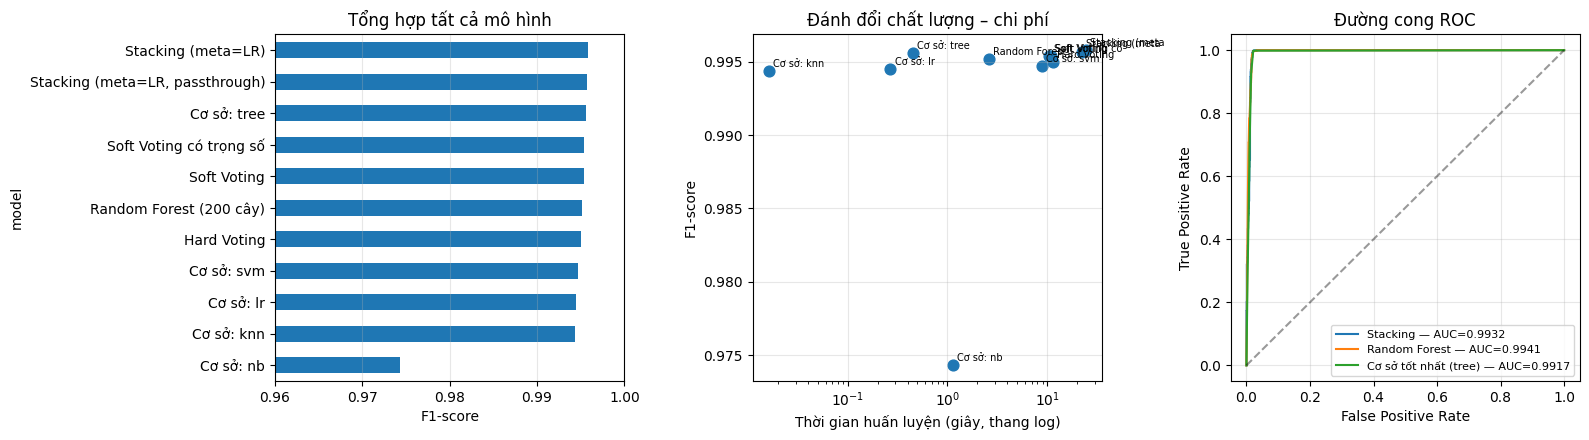

In [10]:
# Tổng hợp tất cả: năm mô hình cơ sở, ba kiểu voting, hai kiểu stacking, và
# Random Forest làm mốc so sánh. Random Forest bản thân cũng là một ensemble
# (bagging 200 cây) nên đây là phép so sánh công bằng giữa hai triết lý:
# kết hợp nhiều thuật toán KHÁC NHAU so với kết hợp nhiều bản sao của CÙNG
# một thuật toán.
rf = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1)
t0 = time.perf_counter()
rf.fit(X_tr, y_tr)
rf_t = time.perf_counter() - t0
rf_sc = rf.predict_proba(X_te)[:, 1]
rf_res = evaluate(y_te, rf.predict(X_te), rf_sc, "Random Forest (200 cây)")
rf_res["fit_s"] = rf_t

all_df = pd.concat([
    base_df.rename(index=lambda s: "Cơ sở: " + s),
    vote_df, stack_df,
    pd.DataFrame([rf_res]).set_index("model"),
]).round(4)
print(all_df[["prec", "rec", "f1", "f1_macro", "auc", "fit_s"]].sort_values(
    "f1", ascending=False).to_string())

WINNER = all_df["f1"].idxmax()
print(f"\n→ Mô hình tốt nhất theo F1: {WINNER} ({all_df.loc[WINNER, 'f1']:.4f})")
print(f"→ Random Forest đứng thứ "
      f"{int((all_df['f1'] > rf_res['f1']).sum()) + 1}/{len(all_df)}")

yp_st = stack_model.predict(X_te)
cm = confusion_matrix(y_te, yp_st)
tn, fp, fn, tp = cm.ravel()
print(f"\nConfusion matrix của Stacking: TN={tn} FP={fp} FN={fn} TP={tp}")
print("\n" + classification_report(y_te, yp_st, target_names=TARGET_NAMES,
                                    digits=4))
print(FINAL_COMMENT)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
all_df["f1"].sort_values().plot.barh(ax=axes[0])
axes[0].set_xlabel("F1-score")
axes[0].set_title("Tổng hợp tất cả mô hình")
axes[0].set_xlim(VOTE_XLIM)
axes[0].grid(axis="x", alpha=.3)

axes[1].scatter(all_df["fit_s"], all_df["f1"], s=60)
for nm, v in all_df.iterrows():
    axes[1].annotate(nm[:14], (v["fit_s"], v["f1"]), fontsize=7,
                     xytext=(3, 3), textcoords="offset points")
axes[1].set_xscale("log")
axes[1].set_xlabel("Thời gian huấn luyện (giây, thang log)")
axes[1].set_ylabel("F1-score")
axes[1].set_title("Đánh đổi chất lượng – chi phí")
axes[1].grid(alpha=.3)

for nm, sc in [("Stacking", stack_model.predict_proba(X_te)[:, 1]),
               ("Random Forest", rf_sc),
               (f"Cơ sở tốt nhất ({BASE_BEST})", probs[BASE_BEST])]:
    fpr, tpr, _ = roc_curve(y_te, sc)
    axes[2].plot(fpr, tpr, label=f"{nm} — AUC={roc_auc_score(y_te, sc):.4f}")
axes[2].plot([0, 1], [0, 1], "k--", alpha=.4)
axes[2].set_xlabel("False Positive Rate")
axes[2].set_ylabel("True Positive Rate")
axes[2].set_title("Đường cong ROC")
axes[2].legend(fontsize=8)
axes[2].grid(alpha=.3)
plt.tight_layout()
plt.show()


### A8. Kiểm Chứng Bằng 5-Fold Cross-Validation

Chạy 5-fold cross-validation mất 146.6 giây

F1 từng fold : [0.9958 0.9935 0.9945 0.9954 0.9939]
F1 trung bình: 0.9946 ± 0.0009
F1 của một lần chia train/test ở A7: 0.9958

Nhận xét: F1 trung bình 0,9946 với độ lệch chuẩn 0,0009 — rất ổn định.
Nhưng hãy để ý thời gian chạy: mỗi fold phải huấn luyện 5 mô hình cơ sở × 5
fold nội bộ, cộng một lần fit cuối. Đây là bài tốn thời gian nhất trong cả
chuỗi năm thuật toán, mà đổi lại gần như không cải thiện gì.


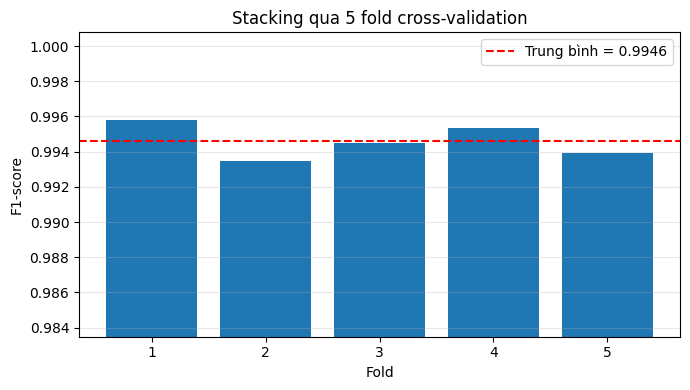

In [11]:
# Toàn bộ stacking — gồm năm Pipeline cơ sở và meta-learner — nằm trong một
# đối tượng duy nhất, nên đưa thẳng vào cross_val_score là an toàn: mỗi fold
# sẽ fit lại tất cả, kể cả các bước tiền xử lý.
#
# Lưu ý về chi phí: mỗi fold phải huấn luyện 5 mô hình cơ sở × 5 fold nội bộ
# cộng một lần fit cuối, nên 5-fold cross-validation ở đây tốn thời gian gấp
# nhiều lần các bài trước.
model_cv = StackingClassifier(
    estimators=make_bases(), final_estimator=make_meta(),
    cv=StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED),
    n_jobs=-1)

cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
t0 = time.perf_counter()
scores = cross_val_score(model_cv, X_raw, y, cv=cv, scoring="f1", n_jobs=1)
print(f"Chạy {CV_FOLDS}-fold cross-validation mất {time.perf_counter()-t0:.1f} giây")

print(f"\nF1 từng fold : {np.round(scores, 4)}")
print(f"F1 trung bình: {scores.mean():.4f} ± {scores.std():.4f}")
print(f"F1 của một lần chia train/test ở A7: "
      f"{stack_df.loc['Stacking (meta=LR)', 'f1']:.4f}")
print(KFOLD_COMMENT)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(range(1, len(scores) + 1), scores)
ax.axhline(scores.mean(), color="red", ls="--",
           label=f"Trung bình = {scores.mean():.4f}")
ax.set_xlabel("Fold")
ax.set_ylabel("F1-score")
ax.set_ylim(min(scores) - 0.01, max(scores) + 0.005)
ax.set_title(f"Stacking qua {CV_FOLDS} fold cross-validation")
ax.legend()
ax.grid(axis="y", alpha=.3)
plt.tight_layout()
plt.show()


---
## Nhận Xét & Câu Hỏi Thảo Luận

**Tổng hợp những gì bài thực hành cho thấy**

1. Năm mô hình cơ sở gần như ngang nhau (F1 0,974–0,996); cây quyết định đơn lẻ dẫn đầu, vượt cả SVM đã dò lưới kỹ.
2. Tính đa dạng rất thấp: bất đồng trung bình chỉ 1,77%, cả năm đồng thuận ở 95,76% số mẫu.
3. Trần số lý tưởng 0,9962 so với 0,9959 của mô hình tốt nhất — khoảng trống cho ensemble chỉ khoảng 0,0003.
4. Voting không cải thiện gì: Soft Voting 0,9954, thấp hơn cây quyết định đơn lẻ.
5. Stacking 0,9958 — nhích hơn voting vì học được trọng số, nhưng vẫn ngang mô hình đơn lẻ.
6. Meta-learner gán Naive Bayes hệ số thấp nhất (0,38), bằng khoảng một phần ba KNN (1,31) — nó tự phát hiện mô hình nào đáng tin.

**Câu hỏi thảo luận**

1. Vì sao "trần số lý tưởng" (oracle accuracy) là giới hạn trên mà không ensemble nào vượt được? Hãy giải thích từ định nghĩa của nó.
2. Bất đồng trung bình chỉ 1,77%. Hãy giải thích vì sao con số thấp này báo trước rằng ensemble sẽ không hiệu quả.
3. Naive Bayes là mô hình yếu nhất nhưng ma trận tương quan lỗi cho thấy nó "khác biệt" nhất. Hai tính chất này ảnh hưởng ngược chiều nhau tới giá trị của nó trong ensemble — hãy phân tích.
4. Stacking hơn Voting dù dữ liệu không đa dạng. Cơ chế nào tạo ra lợi thế đó?
5. Cây quyết định đơn lẻ cho F1 = 0,9956 trong khi Stacking cho 0,9958 nhưng đắt hơn hàng chục lần. Bạn sẽ chọn mô hình nào để triển khai, và trình bày lập luận với người quản lý ra sao?
6. Trên bộ dữ liệu này, kết luận của bài là "ensemble không đáng dùng". Hãy nêu hai đặc điểm của dữ liệu mà nếu thấy chúng, bạn sẽ biết trước điều đó mà không cần chạy thử.
7. Sau năm bài (KNN, Naive Bayes, SVM, phát hiện bất thường, ensemble) trên cùng bộ CICMAL2017, hãy chọn một mô hình để triển khai thực tế và giải thích lựa chọn bằng cả chất lượng, chi phí và khả năng bắt tấn công chưa biết.
